# Module 7 - Lab 3: Titanic - who survived?
**Hands-On Problem 8.1** | Model: k-nearest neighbors (kNN)

**Name:** Roey Kadur 

**GitHub repo:** https://github.com/roee0910/cs82a-portfolio.git

**Goal:** predict whether a passenger survived (`Survived`), prepare my own features, and report accuracy the honest way.

**Honest-evaluation rule:** `titanic_test.csv` has no `Survived` column, so it can never be scored. I build my own test set by splitting `titanic_train.csv` 70/30. The accuracy I report comes only from that held-out 30%.

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 20)

df = pd.read_csv("titanic_train.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
# Which columns have missing values?
missing = df.isna().sum()
missing[missing > 0]

Age         177
Cabin       687
Embarked      2
dtype: int64

`Age` has **177** missing values (as the problem statement says). `Cabin` and `Embarked` also have gaps, but I will not use them.

## 2. Choose and prepare the features
I use 4 numeric-ready features: **Pclass**, **Sex** (encoded 0 = male, 1 = female), **Age**, **Fare**.
- They are simple and known for every passenger.
- Not used: `Name`, `Ticket`, `Cabin` (text or mostly missing) and `PassengerId` (just a row number).
- `Survived` is the answer (`y`), so it must **never** be in `X` (that would be leakage).

In [3]:
# New column, so re-running this cell never breaks the data
df["Sex_code"] = df["Sex"].map({"male": 0, "female": 1})

features = ["Pclass", "Sex_code", "Age", "Fare"]
X = df[features]
y = df["Survived"]

assert "Survived" not in X.columns, "Leakage: Survived is in X!"
print("Features given to the model:", features)
print("Unmapped Sex values:", df["Sex_code"].isna().sum())
print("Leakage check passed: Survived is only in y.")

Features given to the model: ['Pclass', 'Sex_code', 'Age', 'Fare']
Unmapped Sex values: 0
Leakage check passed: Survived is only in y.


## 3. Make an honest test set: split 70/30 first
I split before filling the missing ages, so the test passengers never influence any preparation step. `stratify=y` keeps the survived/died share the same in both parts.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Share who survived - train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Training rows: 623 | Test rows: 268
Share who survived - train: 0.384 | test: 0.384


## 4. Handle the 177 missing ages
**My choice: fill with the median age of the training rows.** The median is not pulled by a few very old or very young passengers (same reasoning as Module 3). The mean would also be defensible. The median comes from the training rows only, and the same number is used for the test rows.

In [5]:
print("Missing ages before - train:", X_train["Age"].isna().sum(),
      "| test:", X_test["Age"].isna().sum())

age_median = X_train["Age"].median()
print("Median age (training rows only):", age_median)

X_train = X_train.fillna({"Age": age_median})
X_test = X_test.fillna({"Age": age_median})

print("Missing values after - train:", int(X_train.isna().sum().sum()),
      "| test:", int(X_test.isna().sum().sum()))

Missing ages before - train: 119 | test: 58
Median age (training rows only): 29.0
Missing values after - train: 0 | test: 0


## 5. Scale the features (kNN needs this)
kNN works with distances. `Fare` (0 to 512) would drown out `Pclass` (1 to 3) if I left the numbers as they are. `StandardScaler` is fitted on the training rows only, then applied to both parts.

In [6]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Scaled training means (about 0):", X_train_s.mean(axis=0).round(2) + 0.0)
print("Scaled training std devs (about 1):", X_train_s.std(axis=0).round(2))

Scaled training means (about 0): [0. 0. 0. 0.]
Scaled training std devs (about 1): [1. 1. 1. 1.]


## 6. Choose k using only the training data
Picking k by looking at the test score would be cheating. Instead I use 5-fold cross-validation inside the training set and keep the test set untouched.

In [7]:
k_values = list(range(1, 26, 2))
cv_scores = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    cv_scores.append(cross_val_score(model, X_train_s, y_train, cv=5).mean())

cv_table = pd.DataFrame({"k": k_values, "cv_accuracy": np.round(cv_scores, 4)})
best_k = int(cv_table.loc[cv_table["cv_accuracy"].idxmax(), "k"])

print("Best k from cross-validation:", best_k)
cv_table

Best k from cross-validation: 11


,k,cv_accuracy
0,1,0.7383
1,3,0.7864
2,5,0.7912
3,7,0.7977
4,9,0.8025
5,11,0.8041
6,13,0.8041
7,15,0.8009
8,17,0.7977
9,19,0.7929


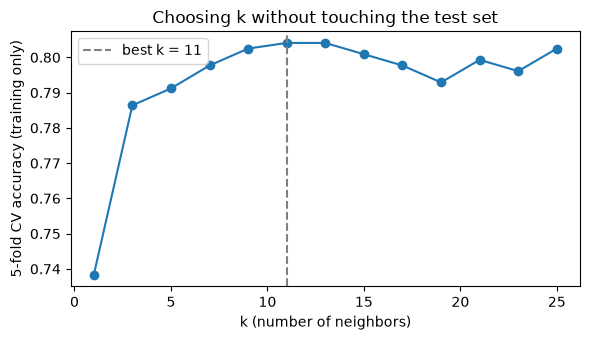

In [8]:
plt.figure(figsize=(6, 3.5))
plt.plot(cv_table["k"], cv_table["cv_accuracy"], marker="o")
plt.axvline(best_k, color="gray", linestyle="--", label="best k = %d" % best_k)
plt.xlabel("k (number of neighbors)")
plt.ylabel("5-fold CV accuracy (training only)")
plt.title("Choosing k without touching the test set")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Fit the final model and score it once on the TEST set

In [9]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_s, y_train)

test_pred = knn.predict(X_test_s)
test_acc = accuracy_score(y_test, test_pred)
train_acc = knn.score(X_train_s, y_train)
baseline_acc = (y_test == 0).mean()   # always guess "died"

print("TEST ACCURACY: %.3f (%.1f%%)" % (test_acc, 100 * test_acc))

pd.DataFrame({
    "Measure": ["TEST accuracy (the honest number)",
                "Training accuracy (for comparison only)",
                "Baseline: guess 'died' for everyone (test)"],
    "Accuracy": [round(test_acc, 3), round(train_acc, 3), round(baseline_acc, 3)]})

TEST ACCURACY: 0.787 (78.7%)


,Measure,Accuracy
0,TEST accuracy (the honest number),0.787
1,Training accuracy (for comparison only),0.828
2,Baseline: guess 'died' for everyone (test),0.616


**Result:** the kNN model (k = 11, 4 features) reaches **78.7% accuracy on the held-out test set** (211 of 268 passengers right). That beats the "everyone died" baseline of 61.6%, so the model has learned something real. The score is not suspiciously high, and there is no leakage.

## 8. Error analysis: who does the model get wrong?

In [10]:
cm = pd.DataFrame(confusion_matrix(y_test, test_pred),
                  index=["Actually died", "Actually survived"],
                  columns=["Predicted died", "Predicted survived"])
print(cm)
print()
print(classification_report(y_test, test_pred, target_names=["died", "survived"]))

                   Predicted died  Predicted survived
Actually died                 143                  22
Actually survived              35                  68

              precision    recall  f1-score   support

        died       0.80      0.87      0.83       165
    survived       0.76      0.66      0.70       103

    accuracy                           0.79       268
   macro avg       0.78      0.76      0.77       268
weighted avg       0.78      0.79      0.78       268



In [11]:
check = X_test.copy()
check["Sex"] = check["Sex_code"].map({0: "male", 1: "female"})
check["actual"] = y_test
check["predicted"] = test_pred
check["wrong"] = check["actual"] != check["predicted"]

by_group = (check.groupby(["Sex", "Pclass"])
            .agg(passengers=("wrong", "count"),
                 n_wrong=("wrong", "sum"),
                 error_rate=("wrong", "mean"),
                 actual_survival_rate=("actual", "mean"),
                 predicted_survival_rate=("predicted", "mean"))
            .round(3)
            .sort_values("error_rate", ascending=False))

print("Overall: %d wrong out of %d (error rate %.3f)" % (
    check["wrong"].sum(), len(check), check["wrong"].mean()))
by_group

Overall: 57 wrong out of 268 (error rate 0.213)


passengers  n_wrong  error_rate  actual_survival_rate  predicted_survival_rate
Sex    Pclass                                                                                
male   1               41       19       0.463                 0.366                    0.195
female 3               44       20       0.455                 0.432                    0.614
male   3              101       14       0.139                 0.139                    0.000
       2               29        2       0.069                 0.138                    0.069
female 2               25        1       0.040                 0.960                    1.000
       1               28        1       0.036                 0.964                    1.000

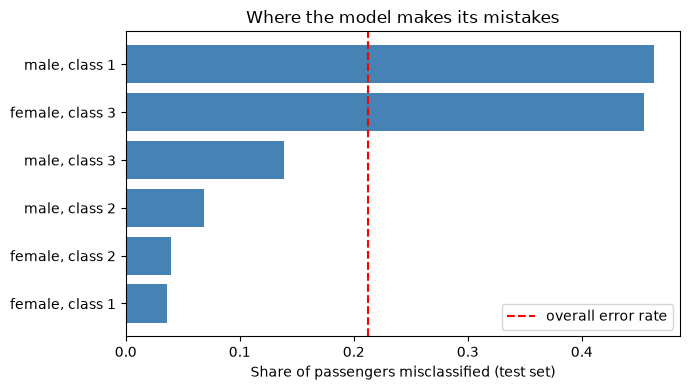

In [12]:
plot_data = by_group.sort_values("error_rate")
labels = ["%s, class %d" % (s, c) for s, c in plot_data.index]

plt.figure(figsize=(7, 4))
plt.barh(labels, plot_data["error_rate"], color="steelblue")
plt.axvline(1 - test_acc, color="red", linestyle="--", label="overall error rate")
plt.xlabel("Share of passengers misclassified (test set)")
plt.title("Where the model makes its mistakes")
plt.legend()
plt.tight_layout()
plt.show()

### Answer (one sentence)
**The model most often gets wrong first-class men (19 of 41 misclassified, 46%) and third-class women (20 of 44, 45%): together only 85 of the 268 test passengers but 39 of its 57 mistakes, because in these two groups survival is close to a coin flip (about 37% and 43% actually survived).**

Extra detail (from the tables above):
- Men in 2nd/3rd class and women in 1st/2nd class are almost always right (error rate 4% to 14%).
- The model misses survivors (35) more often than it raises false alarms (22). With only class, sex, age and fare, it cannot tell which first-class men or third-class women were the lucky ones.

## 9. Context: how stable is the test accuracy?
One split gives one number. To see how much it can move, I repeat the whole recipe (split, fill ages, scale, kNN) on 10 different random 70/30 splits. This is only for context. It does not change my model or my reported score.

In [13]:
accs = []
for seed in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.30, random_state=seed, stratify=y)
    med = Xa["Age"].median()
    Xa = Xa.fillna({"Age": med})
    Xb = Xb.fillna({"Age": med})
    sc = StandardScaler().fit(Xa)
    m = KNeighborsClassifier(n_neighbors=best_k).fit(sc.transform(Xa), ya)
    accs.append(m.score(sc.transform(Xb), yb))

print("Test accuracy over 10 different splits:")
print("lowest %.3f | average %.3f | highest %.3f" % (min(accs), np.mean(accs), max(accs)))

Test accuracy over 10 different splits:
lowest 0.765 | average 0.792 | highest 0.847


## 10. Optional stretch: predict `titanic_test.csv`
Like a Kaggle submission. I **cannot score** these predictions (the file has no `Survived` column), so they are not part of my accuracy.

In [14]:
test_df = pd.read_csv("titanic_test.csv")
print("Has a Survived column?", "Survived" in test_df.columns)

test_df["Sex_code"] = test_df["Sex"].map({"male": 0, "female": 1})
X_new = test_df[features]
print("Missing values before filling:")
print(X_new.isna().sum()[X_new.isna().sum() > 0].to_string())

# Same fill rules as training: use TRAINING medians (one passenger has no Fare)
X_new = X_new.fillna({"Age": age_median, "Fare": X_train["Fare"].median()})
print("Missing values after filling:", int(X_new.isna().sum().sum()))

new_pred = knn.predict(scaler.transform(X_new))
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Survived": new_pred})
submission.to_csv("titanic_predictions.csv", index=False)

print("Predicted survivors: %d of %d" % (new_pred.sum(), len(new_pred)))
submission.head()

Has a Survived column? False
Missing values before filling:
Age     86
Fare     1
Missing values after filling: 0
Predicted survivors: 138 of 418


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


## Summary
- **Model:** kNN, k = 11 (chosen by cross-validation on training data only).
- **Features:** Pclass, Sex (0/1), Age, Fare. Missing ages filled with the training median (29.0). Features scaled.
- **Honest TEST accuracy:** 78.7% on a held-out 30% of `titanic_train.csv` (baseline "everyone died": 61.6%).
- **Who it gets wrong:** see the one-sentence answer in section 8.
- `titanic_test.csv` was used only for the optional predictions, never for scoring.